In [2]:
import pandas as pd
from pathlib import Path
from reed import utils

In [3]:
config = utils.Config()

In [6]:
monitoring_data_path = config.REED_PATH/'Data'/"MonitoringData"

In [19]:
monitoring_data_path = Path.home()/'OneDrive - 2.-0 LCA Consultants ApS'/"REED_ 1277"/"Data"/"MonitoringData"

In [20]:
komatsu_flp7152 = monitoring_data_path/'KOMATSU - FLP-7152'

In [42]:
komatsu_path_1 = list(komatsu_flp7152.glob('*gz'))[1]
komatsu_1 = pd.read_csv(komatsu_path_1)
komatsu_1["timestamp"] = pd.to_datetime(komatsu_1.timestamp)
komatsu_1.head()

,Operation_Mode,Operation_Status,Power_Spindle,Power_X1,Power_X2,Power_Y,Power_Z,timestamp
0,4.0,2.0,0.0,0.55,0.55,0.0,0.275,2025-01-28 11:01:22.281000+00:00
1,4.0,2.0,0.0,0.55,0.55,0.0,0.275,2025-01-28 11:01:23.281000+00:00
2,4.0,2.0,0.0,0.55,0.55,0.0,0.275,2025-01-28 11:01:24.281000+00:00
3,4.0,2.0,0.0,0.55,0.55,0.0,0.275,2025-01-28 11:01:25.281000+00:00
4,4.0,2.0,0.0,0.55,0.55,0.0,0.275,2025-01-28 11:01:26.281000+00:00


In [85]:
komatsu_path_2 = list(komatsu_flp7152.glob('*gz'))[3]
komatsu_2 = pd.read_csv(komatsu_path_2)
komatsu_2["timestamp"] = pd.to_datetime(komatsu_2.timestamp)
komatsu_2.head()

,Feed_Override,Feed_Rate_Actual,Feed_Rate_Commanded,Head_Angular_On,Head_Auto_On,Head_Boring_On,Position_MCS_A,Position_MCS_C,Position_MCS_X,Position_MCS_Y,...,Program_Name,Spindle_Speed_Actual,Spindle_Speed_Commanded,Spindle_Speed_Override,Temperature_Head,Temperature_Room,Temperature_Y,Temperature_Z,Tool_Number,timestamp
0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,-7600.796,733.425,...,UQBC-EXT-BOOM-M,0.0,NaN,7.0,172.0,164.0,194.0,159.0,0.0,2025-01-28 11:01:21.440000+00:00
1,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,-7600.796,733.425,...,UQBC-EXT-BOOM-M,0.0,NaN,7.0,172.0,164.0,194.0,159.0,0.0,2025-01-28 11:01:22.439000+00:00
2,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,-7600.796,733.425,...,UQBC-EXT-BOOM-M,0.0,NaN,7.0,172.0,164.0,194.0,159.0,0.0,2025-01-28 11:01:23.439000+00:00
3,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,-7600.796,733.425,...,UQBC-EXT-BOOM-M,0.0,NaN,7.0,172.0,164.0,194.0,159.0,0.0,2025-01-28 11:01:24.440000+00:00
4,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,-7600.796,733.425,...,UQBC-EXT-BOOM-M,0.0,NaN,7.0,172.0,164.0,194.0,159.0,0.0,2025-01-28 11:01:25.439000+00:00


In [87]:
komatsu_2.sample(1).T

,125719
Feed_Override,100.0
Feed_Rate_Actual,400.0
Feed_Rate_Commanded,NaN
Head_Angular_On,NaN
Head_Auto_On,NaN
Head_Boring_On,NaN
Position_MCS_A,NaN
Position_MCS_C,NaN
Position_MCS_X,-367.127
Position_MCS_Y,-89.4


## Goimek

In [73]:
goimek_path_1 = list((monitoring_data_path/"GOIMEK - PM-10005").glob("*.gz"))[5]
goimek_df = pd.read_csv(goimek_path_1)
goimek_df["timestamp"] = pd.to_datetime(goimek_df.timestamp)
goimek_df.sample().T

,54054
Energy_Total,NaN
Enery_Hours,NaN
Feed_Override,100.0
Feed_Rate_Actual,6088.0
Feed_Rate_Commanded,4000.0
Head_Angular_On,NaN
Head_Auto_On,NaN
Head_Boring_On,NaN
Offset_X,9344.635
Offset_Y,1810.7988


In [90]:
goimek_df.Program_Name.value_counts()

Program_Name
020_ARBAZTATU.H                           13248
040_PUNTAKO_ZULOAK_SEMIAKABATUA.H          5346
207.cyc                                    4056
070_AMAIERA.H                              3935
200.cyc                                    3504
060_ZULOAK_M6_M12_M14_M16_M36.H            1800
toolcall.hbi                               1306
050_ZULOAK_M4_M5_4872110029.H               674
390.H                                       570
397_ANGULAR.H                               378
$mdi.h                                      224
208.cyc                                     191
205.cyc                                     179
ToolCallPre.h                               167
419.CYC                                     132
397_AUTO.H                                  129
TC_Axis_Safe.H                              127
M367.h                                       98
ToolcallPost.h                               65
427.CYC                                      42
tooldef.hbi                

In [77]:
goimek_df.Tool_Number.unique()

array([ 5.,  0.,  1., 44.,  6.,  2., 29., 31., 12., 19., 32., 25., 26.,
        3.,  7., 14.,  8., 15., 13., 20., 34., 33., 35., 36., 27., 28.,
       10., 17., 23.,  4., 24.,  9., 11., 37., 43., 16., 38., 18.])

<Axes: xlabel='timestamp'>

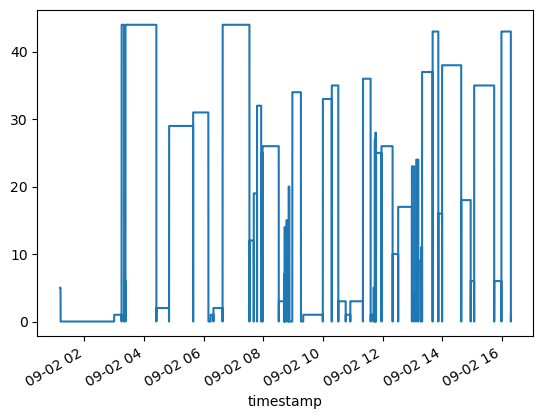

In [ ]:
# tools change over time
goimek_df.set_index('timestamp').Tool_Number.plot()

In [82]:
goimek_df.pivot_table(index='Tool_Number',values='Power_Active',aggfunc=['mean','std'])

,mean,std
,Power_Active,Power_Active
Tool_Number,,
0.0,11.230166,1.322127
1.0,12.029427,1.689400
2.0,14.290751,2.935886
3.0,13.029464,2.418524
4.0,11.800000,0.000000
5.0,11.800000,0.000000
6.0,11.760305,0.205226
7.0,17.750000,0.000000


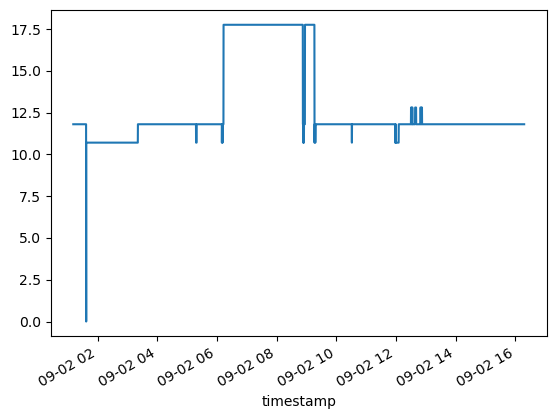

In [78]:
goimek_df.set_index('timestamp').Power_Active.plot();

In [72]:
goimek_path_1 = list((monitoring_data_path/"GOIMEK - PM-10005").glob("*.gz"))[1]
goimek_df = pd.read_csv(goimek_path_1)
goimek_df.head(3).T

,0,1,2
Operation_Mode,3.0,3.0,3.0
Operation_Status,0.0,0.0,0.0
Power_X1,3.456,3.456,3.456
Power_X2,1.536,1.536,1.536
Power_Y,1.344,1.344,1.344
Power_Z,2.3445,2.3445,2.3445
timestamp,2025-09-01T06:15:08.747Z,2025-09-01T06:15:09.747Z,2025-09-01T06:15:10.747Z
